# LeetCode #78: Subsets

https://leetcode.com/problems/subsets/

## Two ways to solve it

| Approach | Time | Space (besides the answer) | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Count through bitmasks** | $O(n \cdot 2^n)$ | $O(1)$ | Treat each number from 0 to $2^n - 1$ as a list of in/out switches. |
| **Backtracking: grow, record, undo ★** | $O(n \cdot 2^n)$ | $O(n)$ | One list that grows and shrinks; every state it passes through is a subset. |

`n` is the length of `nums` (at most 10). Each number is either in a subset or out, so there are $2^n$
subsets: 1,024 when `n = 10`. Writing them out takes about $n$ steps each, which is the
$O(n \cdot 2^n)$: about 5,000 numbers copied at `n = 10`. No approach can beat that, because the answer
itself is that big. The extra memory, apart from the answer, is the working list and the chain of
unfinished calls, each at most `n` long.

A **subset** is any selection of the numbers, including none of them (`[]`) and all of them. Order
inside a subset doesn't matter, so `[1,2]` and `[2,1]` are the same subset and must appear once.

## Understanding the methods

### Count through bitmasks

Count from 0 to $2^n - 1$. Read each number in binary: bit `j` set means "include `nums[j]`". Every
pattern of bits is a different subset, so this lists each exactly once. Short, but the link between a
binary number and a subset is less obvious to read, and it doesn't extend to variations such as
"skip duplicates".

### Optimal: Backtracking: grow, record, undo ★ (the one coded below)

Keep one working list. A recursive function records a copy of it as a subset, then tries adding each
remaining number in turn: add it, recurse, take it off again. "Remaining" means only numbers *after*
the last one added, so every subset is built in index order and `[2,1]` can never be built after
`[1,2]`. Choosing, exploring, and undoing the choice is called **backtracking**.

**Why this is the pick:** same cost as the bitmask, but the structure (choose, recurse, undo) is the
template for a whole family of problems: combinations, permutations, subsets with duplicates.

**Constraints:**
* `1 <= nums.length <= 10`
* `-10 <= nums[i] <= 10`
* All the numbers of `nums` are unique


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Every subset is a set of in-or-out choices, so there are 2 to the n. I'll build them with one working list: a recursive function records a copy of the list, then for each number after the last one I added, adds it, recurses, and removes it. Only looking forward means `[1,2]` is built but `[2,1]` never is. That's 2^n calls, each copying up to n numbers: O(n · 2^n), the size of the answer, so it can't be beaten. The detail that matters is recording a copy, not the list I'm still changing."

The copy is the line I'll be watching for on the board.

---

### I slide the problem across the table

I write `nums = [1,2,3]` and ask for all subsets.

> **You:** "Are the numbers all different?"

**"Yes, all unique."** Good question. With duplicates, `[1,2,2]` would produce `[1,2]` twice, and the code would need a sort and a skip. Knowing it's unique lets you leave that out.

> **You:** "Does the order matter, of the subsets or inside them?"

**"Any order."** That frees you to build them in whatever order the recursion produces.

---

### Now tell me what's actually hard about it

> **You:** "Listing subsets isn't hard. Listing each one exactly once is. If I just say 'pick any number not yet used', I'll build `[1,2]` and later `[2,1]`, which is the same subset. So I need a canonical way to build each one."

> **You:** "If I always build a subset in index order, there's only one way to build it. That means after I add `nums[i]`, the next number can only come from `i + 1` onwards. Then `[2,1]` is impossible, because after choosing 2 I never look back at 1."

That's what I want first: the duplicate problem, then the rule that removes it. The recursion is just how you apply the rule.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "`backtrack(start, path)`. First, record a copy of `path`, because every state it passes through is a valid subset, including the empty one at the start. Then loop `i` from `start` to the end: append `nums[i]`, call `backtrack(i + 1, path)`, pop.
>
> Each call records exactly one subset, so there are 2^n calls: 1,024 at n = 10. The copies add up to n · 2^(n−1) numbers, 5,120 at n = 10, which is the size of the answer. Besides the answer, the memory is `path` and the call stack, both at most n deep."

Good. You counted calls and copies separately, and both came from the code.

Sometimes I ask whether there's another way to shape the recursion.

> **You:** "The other common one is include-or-exclude: at index i, recurse once with `nums[i]` added and once without, and record only when i reaches the end. It's the same 2^n subsets, but they're all at the leaves, so it makes 2^(n+1) − 1 calls instead of 2^n. Both are fine. I prefer the loop version because every call does useful work, and the same loop with a different start gives combinations and permutations."

That tells me you understand both trees, not just the one you memorised.

---

### Now whiteboard it

```
result = []
def backtrack(start, path):
    result.append(list(path))
```

> **You:** "`list(path)`, a copy. `path` is one list I keep changing. If I appended `path` itself, every entry in `result` would be the same list, and when the recursion finishes and pops everything, they'd all be empty."

That's the sentence. Without it, I'd ask you what `result` looks like at the end.

```
    for i in range(start, len(nums)):
        path.append(nums[i])
        backtrack(i + 1, path)
        path.pop()

backtrack(0, [])
return result
```

> **You:** "`i + 1`, not `start + 1`. After I take `nums[i]`, the next pick has to come after `i`. With `start + 1` the loop could pick the same number again, and I'd get `[2,2]`."

> **You:** "And the pop is the undo. When the call for `[1,2]` returns, I take the 2 off so the loop can try `[1,3]`. Without it, the list just keeps growing."

---

### Walk me through it before you say you're done

> **You:** "Record `[]`. Add 1: record `[1]`. Add 2: record `[1,2]`. Add 3: record `[1,2,3]`. Nothing left, return, pop 3, the loop under `[1,2]` is done, pop 2. Under `[1]`, try 3: record `[1,3]`, pop. Back at the top, pop 1, try 2: record `[2]`, then `[2,3]`. Then `[3]`. Eight subsets, none repeated, and `[2]`'s loop started at 3, so `[2,1]` never appeared."

> **You:** "And `[0]`: record `[]`, add 0, record `[0]`. Two subsets. The value doesn't matter, only the index."

---

### Then tell me where it breaks, before I ask

> **You:** "Nothing to optimise in time: the answer has n · 2^n numbers in it, and I produce each once. What it leans on is the uniqueness you promised. With `[1,2,2]` it would return `[1,2]` twice, because the two 2s are different indices. The fix is to sort first, then in the loop skip `nums[i]` when it equals `nums[i-1]` and `i > start`, so equal numbers are only ever chosen in order. That's Subsets II."

> **You:** "The other limit is just size. At n = 10 the answer is 1,024 lists. At n = 20 it's a million lists and about ten million numbers, so the output itself becomes the problem. If the caller only needed to look at each subset once, I'd yield them one at a time instead of building the whole list."

That's the honest version: the assumption it leans on and the fix, then the cost that no algorithm can avoid.

---

### What would worry me

Appending `path` instead of a copy. Recursing with `start + 1`. A version that records only at the leaves and misses every subset that isn't full length. And "it's 2 to the n" with no mention of the n it costs to copy each one.


## Solutions

All four keep one working list: record a copy of it, then for each later number add it, recurse from the next index, and remove it again.

### C#


In [ ]:
public class Solution {
    public IList<IList<int>> Subsets(int[] nums) {
        var result = new List<IList<int>>();
        Backtrack(nums, 0, new List<int>(), result);
        return result;
    }

    // `path` is ONE list that grows and shrinks; every state it passes through is a subset.
    // `start` = first index we may still add, so subsets are built in index order only.
    private void Backtrack(int[] nums, int start, List<int> path, IList<IList<int>> result) {
        // Record a COPY. Adding `path` itself would store the same list over and over,
        // and the pops below would leave every stored entry empty.
        result.Add(new List<int>(path));
        for (int i = start; i < nums.Length; i++) {
            path.Add(nums[i]);
            // i + 1, not start + 1: the next pick must come after nums[i], so [2,1]
            // is never built after [1,2] and no number is used twice
            Backtrack(nums, i + 1, path, result);
            // Undo the choice, so the loop can try the next number in this slot
            path.RemoveAt(path.Count - 1);
        }
    }
}

### Python


In [ ]:
class Solution:
    def subsets(self, nums: list[int]) -> list[list[int]]:
        result = []

        # `path` is ONE list that grows and shrinks; every state it passes through is a subset.
        # `start` = first index we may still add, so subsets are built in index order only.
        def backtrack(start: int, path: list[int]) -> None:
            # Record a COPY. Appending `path` itself would store the same list over and over,
            # and the pops below would leave every stored entry empty.
            result.append(list(path))
            for i in range(start, len(nums)):
                path.append(nums[i])
                # i + 1, not start + 1: the next pick must come after nums[i], so [2,1]
                # is never built after [1,2] and no number is used twice
                backtrack(i + 1, path)
                # Undo the choice, so the loop can try the next number in this slot
                path.pop()

        backtrack(0, [])
        return result

### Go

`subset := make(...); copy(subset, path)` is the copy. A plain `append(result, path)` would store a slice that shares memory with `path`, so later changes to `path` would rewrite subsets already in `result`.


In [ ]:
func subsets(nums []int) [][]int {
    result := [][]int{}
    // ONE slice that grows and shrinks; every state it passes through is a subset
    path := []int{}

    // `start` = first index we may still add, so subsets are built in index order only
    var backtrack func(start int)
    backtrack = func(start int) {
        // Record a COPY. Appending `path` itself would share its backing array,
        // and later appends and truncations would overwrite the stored subsets.
        subset := make([]int, len(path))
        copy(subset, path)
        result = append(result, subset)
        for i := start; i < len(nums); i++ {
            path = append(path, nums[i])
            // i + 1, not start + 1: the next pick must come after nums[i], so [2,1]
            // is never built after [1,2] and no number is used twice
            backtrack(i + 1)
            // Undo the choice, so the loop can try the next number in this slot
            path = path[:len(path)-1]
        }
    }
    backtrack(0)
    return result
}

### Rust


In [ ]:
impl Solution {
    pub fn subsets(nums: Vec<i32>) -> Vec<Vec<i32>> {
        let mut result = Vec::new();
        let mut path = Vec::new();
        Self::backtrack(&nums, 0, &mut path, &mut result);
        result
    }

    // `path` is ONE vector that grows and shrinks; every state it passes through is a subset.
    // `start` = first index we may still add, so subsets are built in index order only.
    fn backtrack(nums: &[i32], start: usize, path: &mut Vec<i32>, result: &mut Vec<Vec<i32>>) {
        // Record a COPY (clone): `path` keeps changing after this line
        result.push(path.clone());
        for i in start..nums.len() {
            path.push(nums[i]);
            // i + 1, not start + 1: the next pick must come after nums[i], so [2,1]
            // is never built after [1,2] and no number is used twice
            Self::backtrack(nums, i + 1, path, result);
            // Undo the choice, so the loop can try the next number in this slot
            path.pop();
        }
    }
}

## Example Scenarios

### 1. Common Case — Three Numbers
**Input:** `nums = [1, 2, 3]`

The working list goes `[]`, `[1]`, `[1,2]`, `[1,2,3]`, then backs up to build `[1,3]`, then `[2]`, `[2,3]`, and
`[3]`. Every state it passes through is recorded, so all $2^3 = 8$ subsets appear, each once.
**Output:** `[[],[1],[1,2],[1,2,3],[1,3],[2],[2,3],[3]]`

### 2. Slightly Complex — A Zero in the Input
**Input:** `nums = [0, 1, 2]`

Zero is treated like any other number: the recursion chooses by position, never by value. Same shape as
scenario 1, 8 subsets. **Output:** `[[],[0],[0,1],[0,1,2],[0,2],[1],[1,2],[2]]`

### 3. Edge Case: Time Factor — The Largest Input
**Input:** `nums = [1, 2, …, 10]`

`n = 10`, the maximum. Each extra number doubles the count, so $2^{10} = 1024$ subsets, one recursive call
each, and 5,120 numbers copied into them in total ($10 \times 2^9$). **Output:** 1,024 subsets

### 4. Edge Case: Space Factor — The Largest Input Again
**Input:** `nums = [1, 2, …, 10]`

The working list and the chain of unfinished calls never hold more than 10 items. The answer is what takes
the space: 1,024 lists holding 5,120 numbers between them. **Output:** 1,024 subsets

### 5. Almost-Impossible but Plausible — Negatives, Zero and the Value Limits
**Input:** `nums = [-10, -5, 0, 5, 10]`

Both ends of the allowed range, plus zero. Nothing changes, because the code never compares values, only
positions. $2^5 = 32$ subsets, from `[]` to `[-10,-5,0,5,10]`. **Output:** 32 subsets


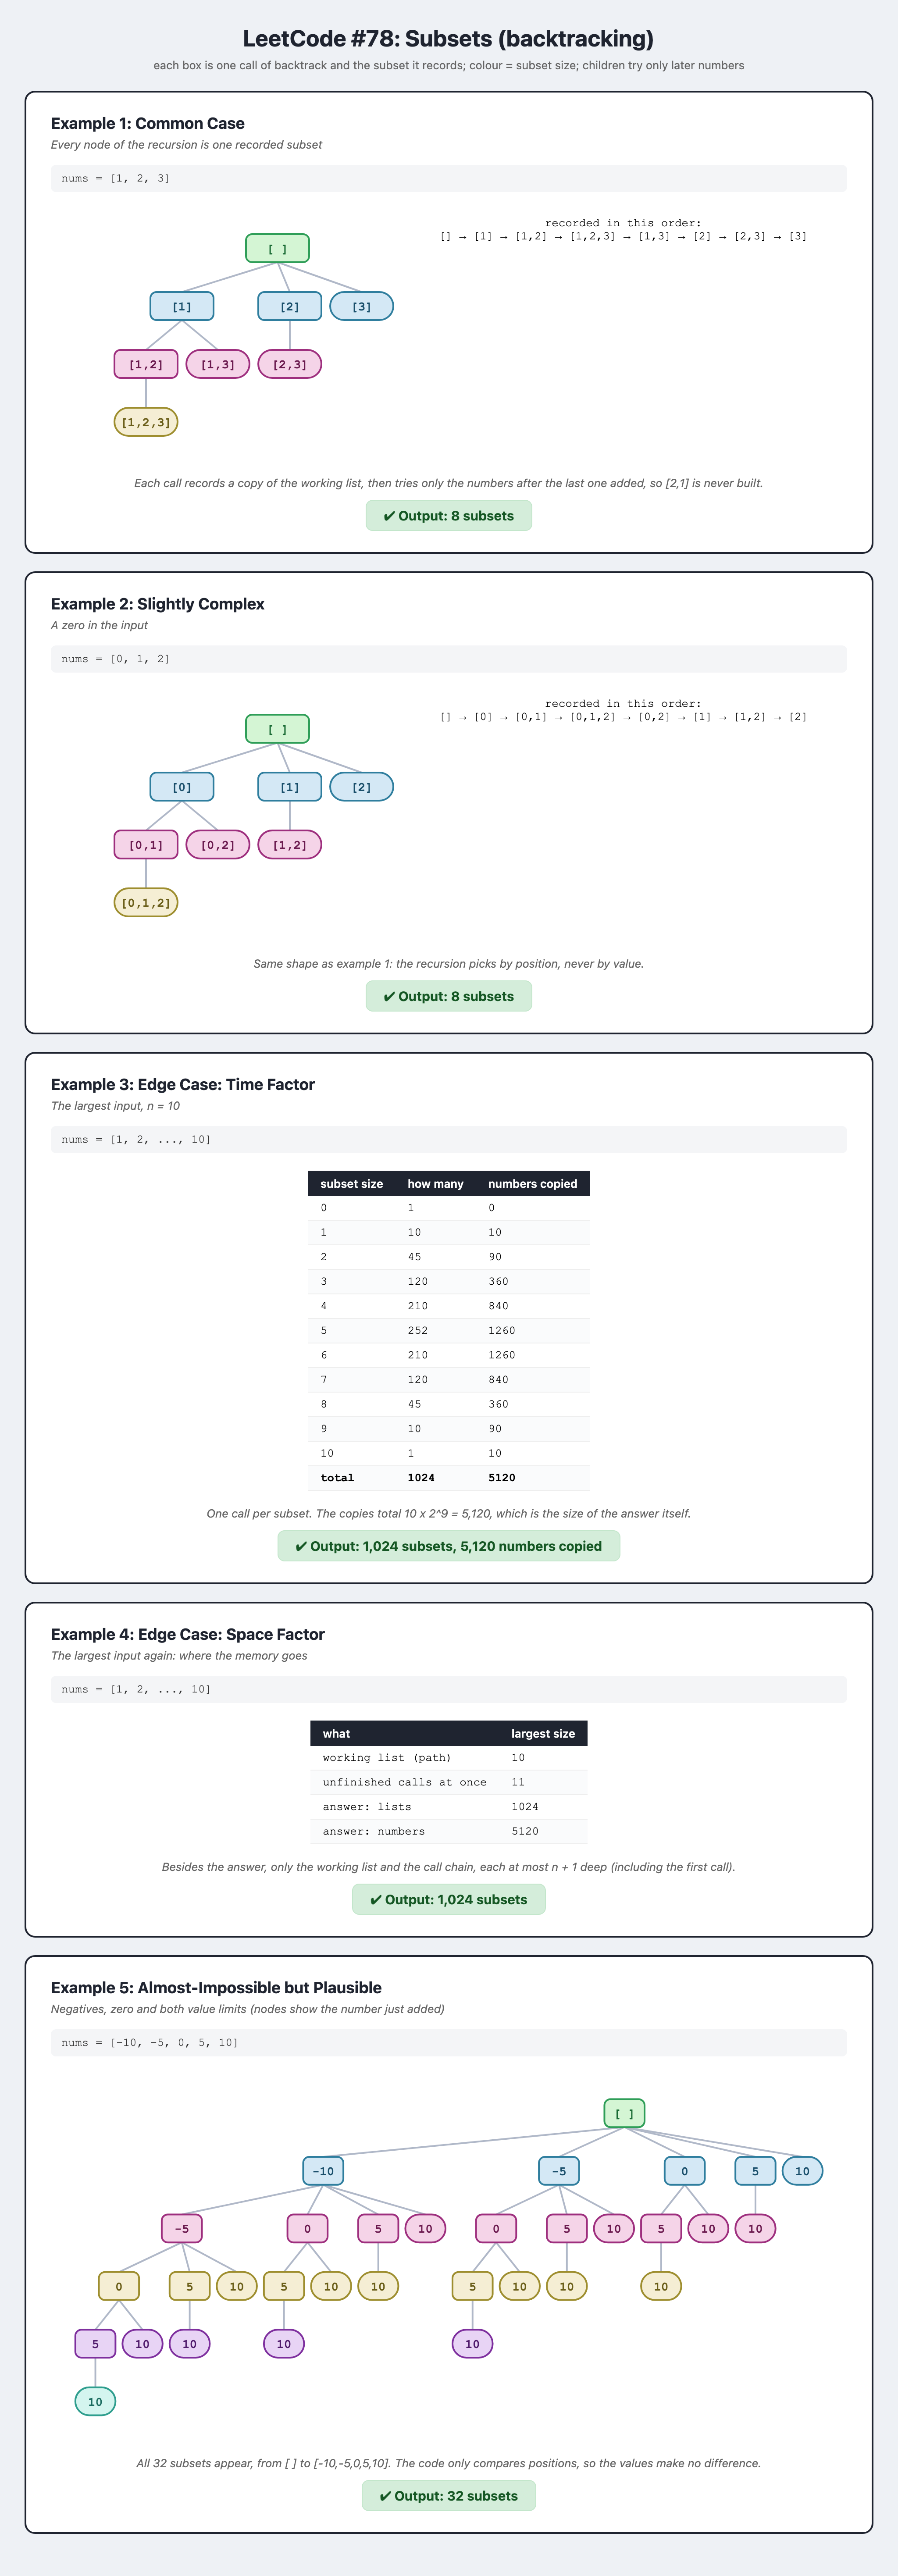

## Watch It Run

*Watch the step back from [1,2,3]: popping 3 is the undo that lets the same working list become [1,3], and copying it at each record is why the answer isn't eight empty lists.*

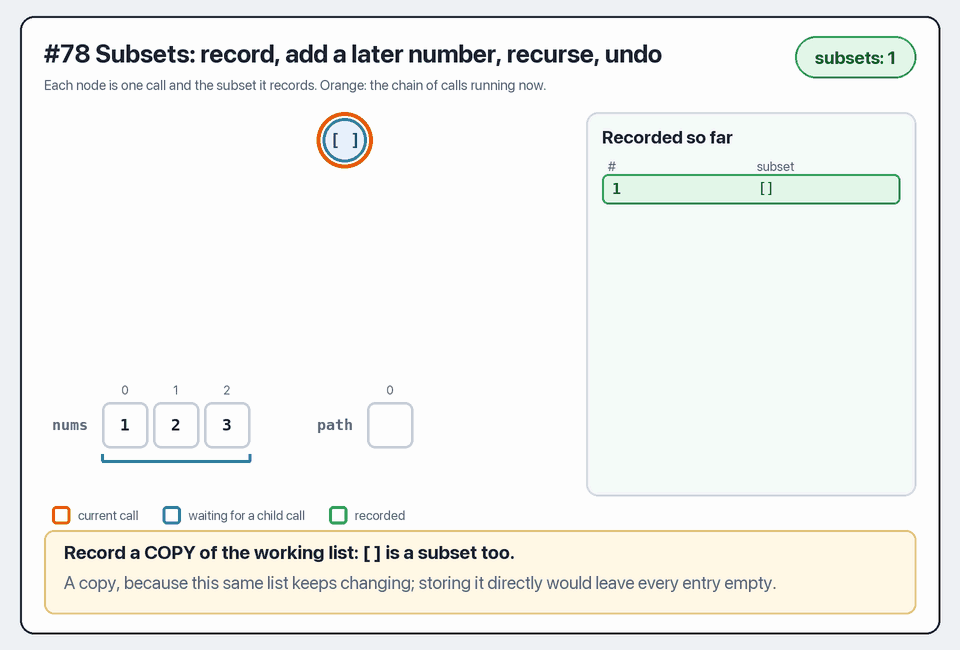